In [1]:

%pip install openpyxl



Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"C:\Users\Dell\OneDrive\Desktop\OIBSIP\Task2_Customer_Segmentation\Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe(include="all").T)


Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

df.columns = df.columns.str.strip()

df = df.drop_duplicates()

df = df.dropna(subset=["CustomerID", "InvoiceDate"])

df = df[df["CustomerID"].notna()]
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

df["CustomerID"] = df["CustomerID"].astype(int)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned dataset shape:", df.shape)
print("Missing values remaining:")
print(df.isnull().sum())

display(df.head())


Cleaned dataset shape: (392692, 9)
Missing values remaining:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [5]:

snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
)

print("RFM table created successfully!")
print("Customer count:", rfm.shape[0])

display(rfm.head(10))


RFM table created successfully!
Customer count: 4338


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40


In [7]:

%pip install scikit-learn


  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl (36.7 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=rfm.columns,
    index=rfm.index
)

print("Standardisation completed!")
display(rfm_scaled_df.head())


Standardisation completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346,2.334574,-0.425097,8.363010
12347,-0.905340,0.354417,0.251699
12348,-0.175360,-0.035340,-0.027988
12349,-0.735345,-0.425097,-0.032406
12350,2.174578,-0.425097,-0.190812


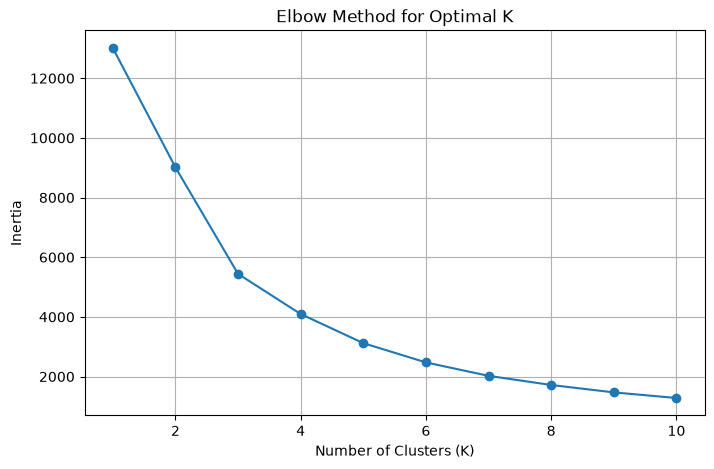

In [9]:

from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(rfm_scaled_df)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()



### Elbow Method

The Elbow Method is used to determine the optimal number of clusters for K-Means clustering. It calculates the Within-Cluster Sum of Squares (WCSS), represented by inertia, for different values of K. The optimal K is estimated by identifying the elbow point where the decrease in inertia becomes less significant.

### Observation

The Elbow Method graph helps identify a suitable number of customer segments. The selected number of clusters will be used to group customers based on their Recency, Frequency, and Monetary values.


In [20]:

print(df.columns.tolist())


['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalAmount']


In [21]:

import pandas as pd

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

customer_clv = df.groupby("CustomerID").agg(
    Total_Revenue=("TotalAmount", "sum"),
    First_Purchase=("InvoiceDate", "min"),
    Last_Purchase=("InvoiceDate", "max"),
    Total_Transactions=("InvoiceNo", "nunique")
).reset_index()

customer_clv["Observed_Lifespan_Days"] = (
    customer_clv["Last_Purchase"] -
    customer_clv["First_Purchase"]
).dt.days

customer_clv["Historical_CLV"] = customer_clv["Total_Revenue"]

customer_clv.head()


,CustomerID,Total_Revenue,First_Purchase,Last_Purchase,Total_Transactions,Observed_Lifespan_Days,Historical_CLV
0,12346,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00,1,0,77183.60
1,12347,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00,7,365,4310.00
2,12348,1797.24,2010-12-16 19:09:00,2011-09-25 13:13:00,4,282,1797.24
3,12349,1757.55,2011-11-21 09:51:00,2011-11-21 09:51:00,1,0,1757.55
4,12350,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00,1,0,334.40


In [22]:

print("Total Customers:", len(customer_clv))
print("Average Historical CLV:", round(customer_clv["Historical_CLV"].mean(), 2))
print("Highest Historical CLV:", round(customer_clv["Historical_CLV"].max(), 2))
print("Lowest Historical CLV:", round(customer_clv["Historical_CLV"].min(), 2))



Total Customers: 4338
Average Historical CLV: 2048.69
Highest Historical CLV: 280206.02
Lowest Historical CLV: 3.75


In [24]:

print("RFM columns:")
print(rfm.columns.tolist())

print("\nRFM first 5 rows:")
print(rfm.head())


RFM columns:
['Recency', 'Frequency', 'Monetary', 'Cluster']

RFM first 5 rows:
            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346           326          1  77183.60        0
12347             2          7   4310.00        1
12348            75          4   1797.24        1
12349            19          1   1757.55        1
12350           310          1    334.40        0


In [25]:

print("Available variables:")
print([name for name in globals() if "rfm" in name.lower() or "cluster" in name.lower()])


Available variables:
['rfm', 'rfm_scaled', 'rfm_scaled_df', 'cluster_counts', 'cluster_profile', 'cluster_id']


In [26]:

customer_clv["CustomerID"] = customer_clv["CustomerID"].astype(int)

rfm_clv = rfm.reset_index()

rfm_clv["CustomerID"] = rfm_clv["CustomerID"].astype(int)

rfm_clv = rfm_clv.merge(
    customer_clv[["CustomerID", "Historical_CLV"]],
    on="CustomerID",
    how="left"
)

cluster_clv_summary = rfm_clv.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_CLV=("Historical_CLV", "mean"),
    Total_Revenue=("Historical_CLV", "sum")
).reset_index()

print(cluster_clv_summary.round(2))



   Cluster  Customer_Count  Average_CLV  Total_Revenue
0        0            1082       629.66      681296.11
1        1            3230      1849.67     5974434.75
2        2              26     85826.08     2231478.03


In [27]:

print("Average Purchase Value:",
      round(df["TotalAmount"].mean(), 2))

print("Average Purchase Frequency:",
      round(df.groupby("CustomerID")["InvoiceNo"].nunique().mean(), 2))


Average Purchase Value: 22.63
Average Purchase Frequency: 4.27


In [10]:

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled_df)

print("Customer clustering completed!")
print("\nCustomers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

display(rfm.head(10))


Customer clustering completed!

Customers in each cluster:
Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,0
12347,2,7,4310.00,1
12348,75,4,1797.24,1
12349,19,1,1757.55,1
12350,310,1,334.40,0
12352,36,8,2506.04,1
12353,204,1,89.00,0
12354,232,1,1079.40,0
12355,214,1,459.40,0


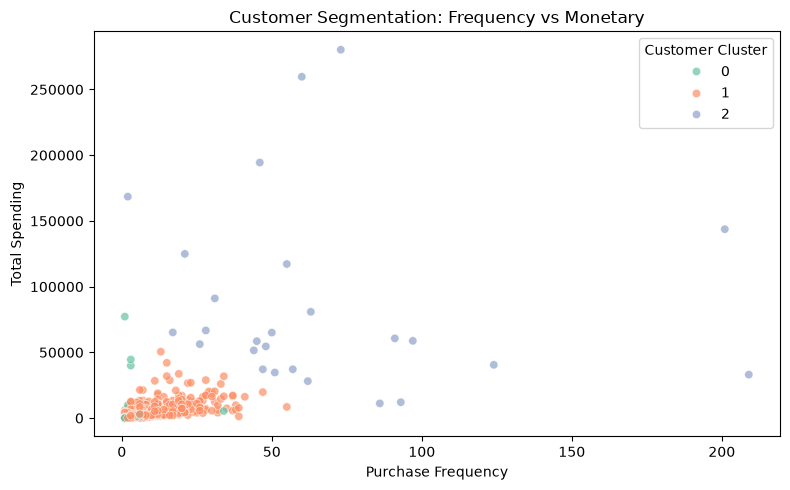

In [11]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)

plt.title("Customer Segmentation: Frequency vs Monetary")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")
plt.legend(title="Customer Cluster")
plt.tight_layout()
plt.show()



### Customer Segmentation: Frequency vs Monetary

This scatter plot visualizes customer segments based on purchase frequency and total spending. Each point represents a customer, and different colors indicate the clusters identified by the K-Means algorithm.

### Observation

The graph helps compare customers based on how frequently they purchase and how much they spend. Customers with higher purchase frequency and monetary value may represent valuable customers, while customers with lower values may need targeted marketing strategies.


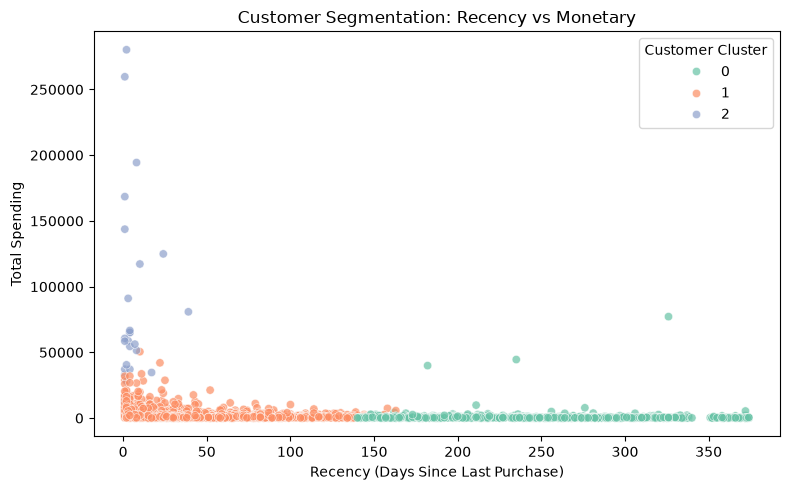

In [12]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)

plt.title("Customer Segmentation: Recency vs Monetary")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Total Spending")
plt.legend(title="Customer Cluster")
plt.tight_layout()
plt.show()



### Customer Segmentation: Recency vs Monetary

This scatter plot compares customers based on recency and total spending. Recency indicates the number of days since a customer's last purchase. Different colors represent the customer clusters identified by K-Means.

### Observation

Customers with lower recency values have purchased more recently. Customers with higher monetary values have spent more overall. This graph helps identify recently active, high-spending customers and customers who may need re-engagement campaigns.


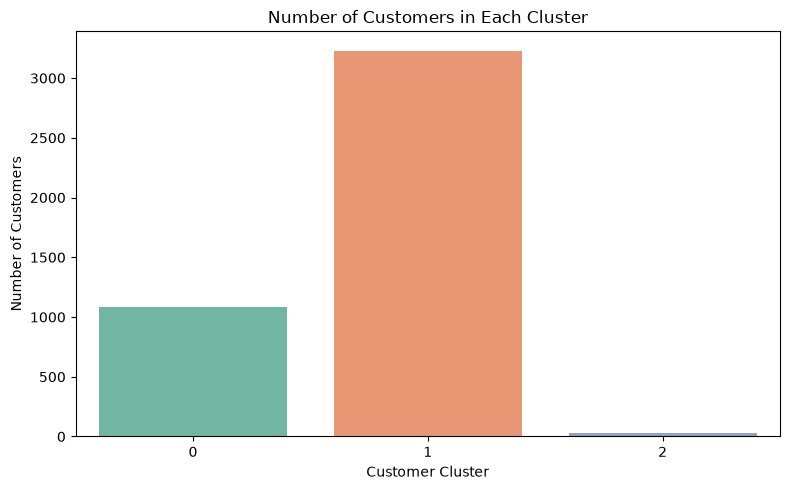

In [13]:

cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values,
    hue=cluster_counts.index.astype(str),
    palette="Set2",
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()



### Number of Customers in Each Cluster

This bar chart shows the number of customers assigned to each cluster by the K-Means algorithm. It helps compare the sizes of the identified customer segments.

### Observation

The chart reveals how customers are distributed across the three clusters. A larger cluster contains more customers, while a smaller cluster represents a more specific customer segment. Businesses can use this information to plan suitable marketing strategies for each group.


In [14]:

cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
).round(2)

print("Customer Cluster Profiles")
display(cluster_profile)


Customer Cluster Profiles


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,1082,247.11,1.58,629.66
1,3230,41.45,4.67,1849.67
2,26,6.04,66.42,85826.08



### Cluster Profile Analysis

Cluster profiling summarizes customer behaviour using average Recency, Frequency, and Monetary values. These metrics help compare the activity, purchase frequency, and spending patterns of customers in each segment.

### Observation

Customers with lower average recency have purchased more recently. Customers with higher average frequency purchase more often, while customers with higher average monetary value contribute more revenue. These differences help businesses understand each segment and develop targeted marketing strategies.


In [15]:

def identify_customer_type(row):
    if row["Average_Recency"] <= cluster_profile["Average_Recency"].median() and row["Average_Frequency"] >= cluster_profile["Average_Frequency"].median() and row["Average_Monetary"] >= cluster_profile["Average_Monetary"].median():
        return "High-Value Active Customers"
    elif row["Average_Recency"] > cluster_profile["Average_Recency"].median():
        return "At-Risk or Inactive Customers"
    elif row["Average_Frequency"] >= cluster_profile["Average_Frequency"].median():
        return "Regular Customers"
    else:
        return "Low-Engagement Customers"

cluster_profile["Customer_Type"] = cluster_profile.apply(identify_customer_type, axis=1)

display(cluster_profile)


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Customer_Type
Cluster,,,,,
0,1082,247.11,1.58,629.66,At-Risk or Inactive Customers
1,3230,41.45,4.67,1849.67,High-Value Active Customers
2,26,6.04,66.42,85826.08,High-Value Active Customers



### Customer Segment Interpretation

The customer segments are interpreted using average Recency, Frequency, and Monetary values. High-value active customers purchase relatively recently and frequently and contribute higher spending. At-risk customers have higher recency values, indicating that they have not purchased recently. Regular customers show repeated purchasing behaviour, while low-engagement customers may require strategies to encourage additional purchases.

### Business Importance

Understanding customer segments helps businesses personalize promotions, improve customer retention, reward loyal buyers, and reconnect with inactive customers.


In [16]:

average_purchase_value = df.groupby("InvoiceNo")["TotalAmount"].sum().mean()

average_purchase_frequency = rfm["Frequency"].mean()

average_customer_value = rfm["Monetary"].mean()

customer_lifespan_days = (
    df.groupby("CustomerID")["InvoiceDate"].max()
    - df.groupby("CustomerID")["InvoiceDate"].min()
).dt.days.mean()

print("Average Purchase Value:", round(average_purchase_value, 2))
print("Average Purchase Frequency:", round(average_purchase_frequency, 2))
print("Average Customer Monetary Value:", round(average_customer_value, 2))
print("Average Observed Customer Lifespan (Days):", round(customer_lifespan_days, 2))


Average Purchase Value: 479.56
Average Purchase Frequency: 4.27
Average Customer Monetary Value: 2048.69
Average Observed Customer Lifespan (Days): 130.45



### Business Metrics Analysis

Business metrics provide an overview of purchasing behaviour in the online retail dataset. Average purchase value measures the average sales amount per invoice, while average purchase frequency measures the number of distinct invoices per customer. Average customer monetary value represents the average total spending per customer.

### Observation

These metrics help businesses understand typical transaction values, customer purchasing activity, and spending patterns. The observed customer lifespan describes the period between a customer's first and last recorded purchases in the dataset. It should not be interpreted as a prediction of future customer lifetime.


In [17]:

recommendations = {
    "High-Value Active Customers": "Provide loyalty rewards, exclusive offers, and early access to new products.",
    "At-Risk or Inactive Customers": "Send re-engagement emails, personalized discounts, and reminders about new products.",
    "Regular Customers": "Encourage repeat purchases through loyalty points, bundles, and personalized product suggestions.",
    "Low-Engagement Customers": "Use introductory offers, targeted promotions, and product recommendations to encourage purchases."
}

cluster_profile["Marketing_Recommendation"] = cluster_profile["Customer_Type"].map(recommendations)

display(cluster_profile[[
    "Customer_Count",
    "Average_Recency",
    "Average_Frequency",
    "Average_Monetary",
    "Customer_Type",
    "Marketing_Recommendation"
]])


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Customer_Type,Marketing_Recommendation
Cluster,,,,,,
0,1082,247.11,1.58,629.66,At-Risk or Inactive Customers,"Send re-engagement emails, personalized discou..."
1,3230,41.45,4.67,1849.67,High-Value Active Customers,"Provide loyalty rewards, exclusive offers, and..."
2,26,6.04,66.42,85826.08,High-Value Active Customers,"Provide loyalty rewards, exclusive offers, and..."



### Marketing Recommendations

Different customer segments require different marketing strategies.

- **High-Value Active Customers:** Offer loyalty rewards, exclusive promotions, and early access to new products to retain valuable customers.
- **At-Risk or Inactive Customers:** Send personalized reminders and targeted discounts to encourage customers to return.
- **Regular Customers:** Use loyalty points, product bundles, and personalized recommendations to increase repeat purchases.
- **Low-Engagement Customers:** Provide suitable introductory offers and relevant product suggestions to encourage further purchases.

### Business Insight

Customer segmentation enables businesses to allocate marketing resources more effectively. Personalized strategies can improve customer retention, encourage repeat purchases, and support revenue growth.


In [18]:

print("FINAL CUSTOMER SEGMENTATION INSIGHTS")
print("=" * 45)

print("\nTotal Customers Analyzed:", len(rfm))
print("Total Customer Clusters:", rfm["Cluster"].nunique())
print("Total Transactions Analyzed:", df["InvoiceNo"].nunique())
print("Total Sales Revenue:", round(df["TotalAmount"].sum(), 2))

print("\nCustomer Distribution:")
display(cluster_profile[[
    "Customer_Count",
    "Average_Recency",
    "Average_Frequency",
    "Average_Monetary",
    "Customer_Type"
]])

print("\nRecommended Business Actions:")
for cluster_id, row in cluster_profile.iterrows():
    print(f"\nCluster {cluster_id}: {row['Customer_Type']}")
    print(row["Marketing_Recommendation"])


FINAL CUSTOMER SEGMENTATION INSIGHTS

Total Customers Analyzed: 4338
Total Customer Clusters: 3
Total Transactions Analyzed: 18532
Total Sales Revenue: 8887208.89

Customer Distribution:


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Customer_Type
Cluster,,,,,
0,1082,247.11,1.58,629.66,At-Risk or Inactive Customers
1,3230,41.45,4.67,1849.67,High-Value Active Customers
2,26,6.04,66.42,85826.08,High-Value Active Customers



Recommended Business Actions:

Cluster 0: At-Risk or Inactive Customers
Send re-engagement emails, personalized discounts, and reminders about new products.

Cluster 1: High-Value Active Customers
Provide loyalty rewards, exclusive offers, and early access to new products.

Cluster 2: High-Value Active Customers
Provide loyalty rewards, exclusive offers, and early access to new products.



## Final Insights and Conclusion

The Online Retail dataset was analyzed to understand customer purchasing behaviour. After cleaning the data, Recency, Frequency, and Monetary (RFM) features were calculated for each customer. The features were standardized, and the K-Means algorithm was used to group customers into three segments.

The visualizations and cluster profiles help compare customers according to their recent activity, purchase frequency, and total spending. The analysis also provides a basis for developing targeted marketing strategies for different customer groups.

### Conclusion

Customer segmentation helps businesses understand customer behaviour and design more effective marketing campaigns. The findings can support customer retention, repeat purchases, personalized promotions, and improved marketing decisions. The results represent patterns in the available historical dataset and do not guarantee future customer behaviour.
